<a href="https://colab.research.google.com/github/2y9838c/supermarket-analysis/blob/main/Supermarket_sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings


In [4]:
df =pd.read_csv("supermarket_sales.csv")

In [5]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [6]:
print(df.head())

    Invoice ID Branch       City Customer type  Gender  \
0  750-67-8428      A     Yangon        Member  Female   
1  226-31-3081      C  Naypyitaw        Normal  Female   
2  631-41-3108      A     Yangon        Normal    Male   
3  123-19-1176      A     Yangon        Member    Male   
4  373-73-7910      A     Yangon        Normal    Male   

             Product line  Unit price  Quantity   Tax 5%     Total       Date  \
0       Health and beauty       74.69         7  26.1415  548.9715   1/5/2019   
1  Electronic accessories       15.28         5   3.8200   80.2200   3/8/2019   
2      Home and lifestyle       46.33         7  16.2155  340.5255   3/3/2019   
3       Health and beauty       58.22         8  23.2880  489.0480  1/27/2019   
4       Sports and travel       86.31         7  30.2085  634.3785   2/8/2019   

    Time      Payment    cogs  gross margin percentage  gross income  Rating  
0  13:08      Ewallet  522.83                 4.761905       26.1415     9.1  
1  10:

In [7]:
print(df.shape)

(1000, 17)


In [10]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  

In [11]:
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

In [12]:
print(df.describe())
print("\n")

        Unit price     Quantity       Tax 5%        Total        cogs  \
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.00000   
mean     55.672130     5.510000    15.379369   322.966749   307.58738   
std      26.494628     2.923431    11.708825   245.885335   234.17651   
min      10.080000     1.000000     0.508500    10.678500    10.17000   
25%      32.875000     3.000000     5.924875   124.422375   118.49750   
50%      55.230000     5.000000    12.088000   253.848000   241.76000   
75%      77.935000     8.000000    22.445250   471.350250   448.90500   
max      99.960000    10.000000    49.650000  1042.650000   993.00000   

       gross margin percentage  gross income      Rating  
count             1.000000e+03   1000.000000  1000.00000  
mean              4.761905e+00     15.379369     6.97270  
std               6.131498e-14     11.708825     1.71858  
min               4.761905e+00      0.508500     4.00000  
25%               4.761905e+00      5.924875   

In [13]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [14]:
# 4. Clean Column Names

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("%", "pct")
)

In [15]:
# إعادة تسمية بعض الأعمدة للتوضيح
df = df.rename(columns={
    "tax_5pct": "tax_5_percent",
    "gross_margin_percentage": "gross_margin_pct"
})

print("New column names:")
print(df.columns.tolist())
print("\n")

New column names:
['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5_percent', 'total', 'date', 'time', 'payment', 'cogs', 'gross_margin_pct', 'gross_income', 'rating']




In [16]:
# تحويل التاريخ والوقت لـ datetime
df["datetime"] = pd.to_datetime(df["date"] + " " + df["time"], format="%m/%d/%Y %H:%M")

In [17]:
# استخراج ميزات مفيدة
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["month_name"] = df["datetime"].dt.month_name()
df["day"] = df["datetime"].dt.day
df["day_of_week"] = df["datetime"].dt.day_name()
df["hour"] = df["datetime"].dt.hour
df["is_weekend"] = df["datetime"].dt.dayofweek.isin([5, 6]).astype(int)

In [18]:
def time_of_day(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

df["time_of_day"] = df["hour"].apply(time_of_day)

In [19]:
# تصنيف التقييم
df["rating_category"] = pd.cut(
    df["rating"],
    bins=[0, 5, 7, 8.5, 10],
    labels=["Poor", "Average", "Good", "Excellent"]
)

print("New features added successfully!")
print("Final shape:", df.shape)
df.head()

New features added successfully!
Final shape: (1000, 27)


,invoice_id,branch,city,customer_type,gender,product_line,unit_price,quantity,tax_5_percent,total,...,datetime,year,month,month_name,day,day_of_week,hour,is_weekend,time_of_day,rating_category
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,2019-01-05 13:08:00,2019,1,January,5,Saturday,13,1,Afternoon,Excellent
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,...,2019-03-08 10:29:00,2019,3,March,8,Friday,10,0,Morning,Excellent
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,...,2019-03-03 13:23:00,2019,3,March,3,Sunday,13,1,Afternoon,Good
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,...,2019-01-27 20:33:00,2019,1,January,27,Sunday,20,1,Evening,Good
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,...,2019-02-08 10:37:00,2019,2,February,8,Friday,10,0,Morning,Average


In [37]:
print(f"\n Total Revenue          : ${df['total'].sum():,.2f}")
print(f" Total Gross Income     : ${df['gross_income'].sum():,.2f}")
print(f" Average Transaction    : ${df['total'].mean():.2f}")
print(f" Average Rating         : {df['rating'].mean():.2f} / 10")
print(f" Total Quantity Sold    : {df['quantity'].sum():,}")
print(f" Number of Invoices     : {df['invoice_id'].nunique()}")


 Total Revenue          : $322,966.75
 Total Gross Income     : $15,379.37
 Average Transaction    : $322.97
 Average Rating         : 6.97 / 10
 Total Quantity Sold    : 5,510
 Number of Invoices     : 1000


In [38]:
print("\n" + "-"*50)
print(" Revenue by City:")
print(df.groupby("city")["total"].agg(["sum", "mean", "count"]).round(2).sort_values("sum", ascending=False))


--------------------------------------------------
 Revenue by City:
                 sum    mean  count
city                               
Naypyitaw  110568.71  337.10    328
Yangon     106200.37  312.35    340
Mandalay   106197.67  319.87    332


In [34]:
print("\n" + "-"*50)
print(" Revenue by Product Line:")
print(df.groupby("product_line")["total"].agg(["sum", "mean", "count"]).round(2).sort_values("sum", ascending=False))


--------------------------------------------------
 Revenue by Product Line:
                             sum    mean  count
product_line                                   
Food and beverages      56144.84  322.67    174
Sports and travel       55122.83  332.07    166
Electronic accessories  54337.53  319.63    170
Fashion accessories     54305.90  305.09    178
Home and lifestyle      53861.91  336.64    160
Health and beauty       49193.74  323.64    152


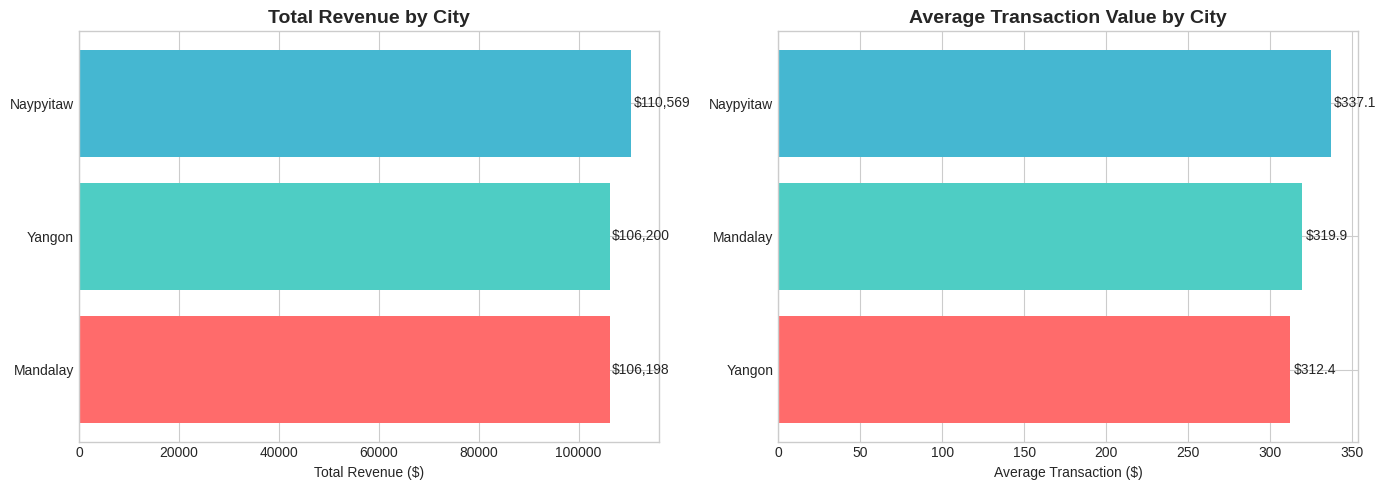

In [21]:

# 7. Visualization 1: Revenue by City


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Total Revenue by City
city_rev = df.groupby("city")["total"].sum().sort_values(ascending=True)
axes[0].barh(city_rev.index, city_rev.values, color=["#FF6B6B", "#4ECDC4", "#45B7D1"])
axes[0].set_title("Total Revenue by City", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Total Revenue ($)")
for i, v in enumerate(city_rev.values):
    axes[0].text(v + 500, i, f"${v:,.0f}", va="center", fontsize=10)

# Average Transaction by City
city_avg = df.groupby("city")["total"].mean().sort_values(ascending=True)
axes[1].barh(city_avg.index, city_avg.values, color=["#FF6B6B", "#4ECDC4", "#45B7D1"])
axes[1].set_title("Average Transaction Value by City", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Average Transaction ($)")
for i, v in enumerate(city_avg.values):
    axes[1].text(v + 2, i, f"${v:.1f}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

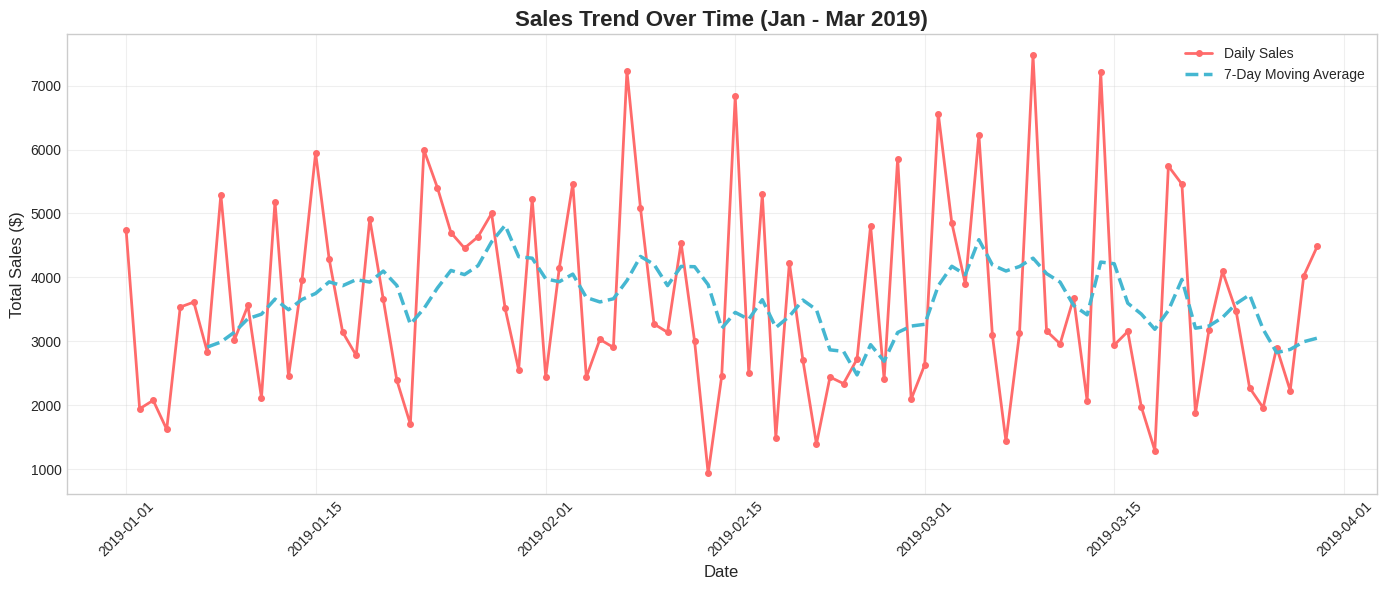

In [22]:
# ======================
# 8. Line Chart: Sales Trend Over Time
# ======================

# تجميع المبيعات اليومية
daily_sales = df.groupby(df["datetime"].dt.date)["total"].sum().reset_index()
daily_sales.columns = ["date", "total_sales"]
daily_sales["date"] = pd.to_datetime(daily_sales["date"])

# الرسم
plt.figure(figsize=(14, 6))

plt.plot(daily_sales["date"], daily_sales["total_sales"],
         color="#FF6B6B", linewidth=2, marker="o", markersize=4, label="Daily Sales")

# إضافة متوسط متحرك (7 أيام) عشان نشوف الاتجاه أوضح
daily_sales["moving_avg"] = daily_sales["total_sales"].rolling(window=7).mean()
plt.plot(daily_sales["date"], daily_sales["moving_avg"],
         color="#45B7D1", linewidth=2.5, linestyle="--", label="7-Day Moving Average")

plt.title("Sales Trend Over Time (Jan - Mar 2019)", fontsize=16, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

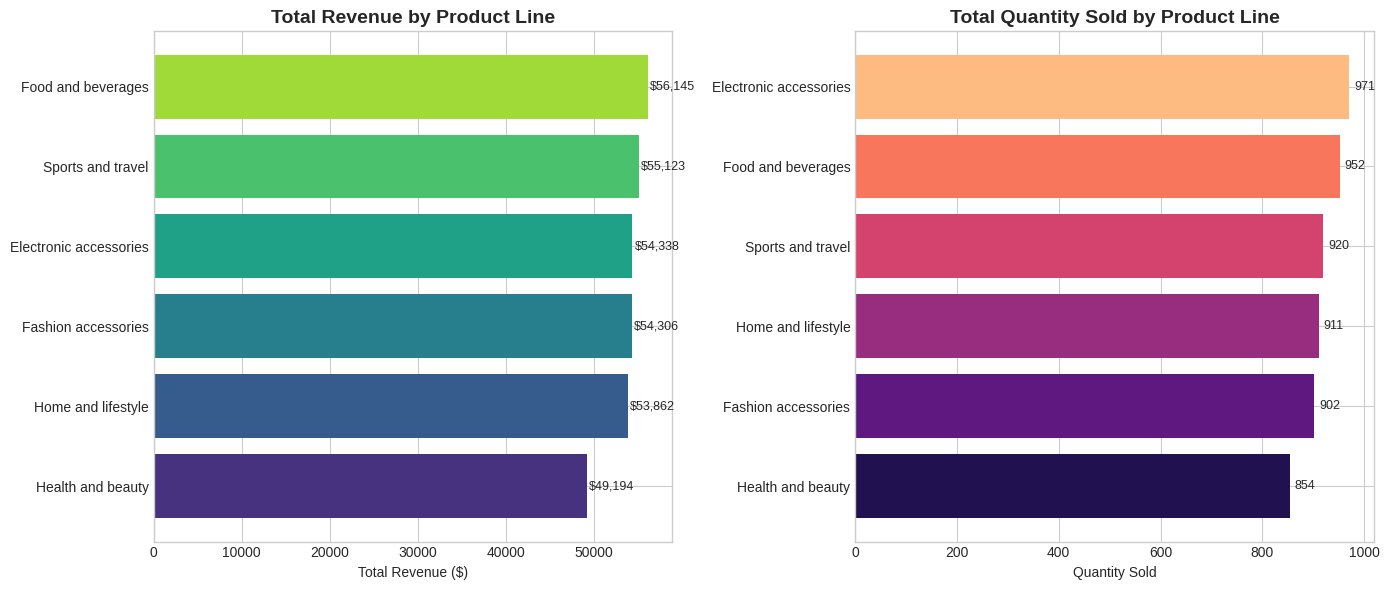

In [23]:
# ======================
# 9. Product Line Analysis
# ======================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Total Revenue by Product Line
prod_rev = df.groupby("product_line")["total"].sum().sort_values(ascending=True)
axes[0].barh(prod_rev.index, prod_rev.values, color=sns.color_palette("viridis", len(prod_rev)))
axes[0].set_title("Total Revenue by Product Line", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Total Revenue ($)")
for i, v in enumerate(prod_rev.values):
    axes[0].text(v + 300, i, f"${v:,.0f}", va="center", fontsize=9)

# Total Quantity Sold by Product Line
prod_qty = df.groupby("product_line")["quantity"].sum().sort_values(ascending=True)
axes[1].barh(prod_qty.index, prod_qty.values, color=sns.color_palette("magma", len(prod_qty)))
axes[1].set_title("Total Quantity Sold by Product Line", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Quantity Sold")
for i, v in enumerate(prod_qty.values):
    axes[1].text(v + 10, i, f"{v}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

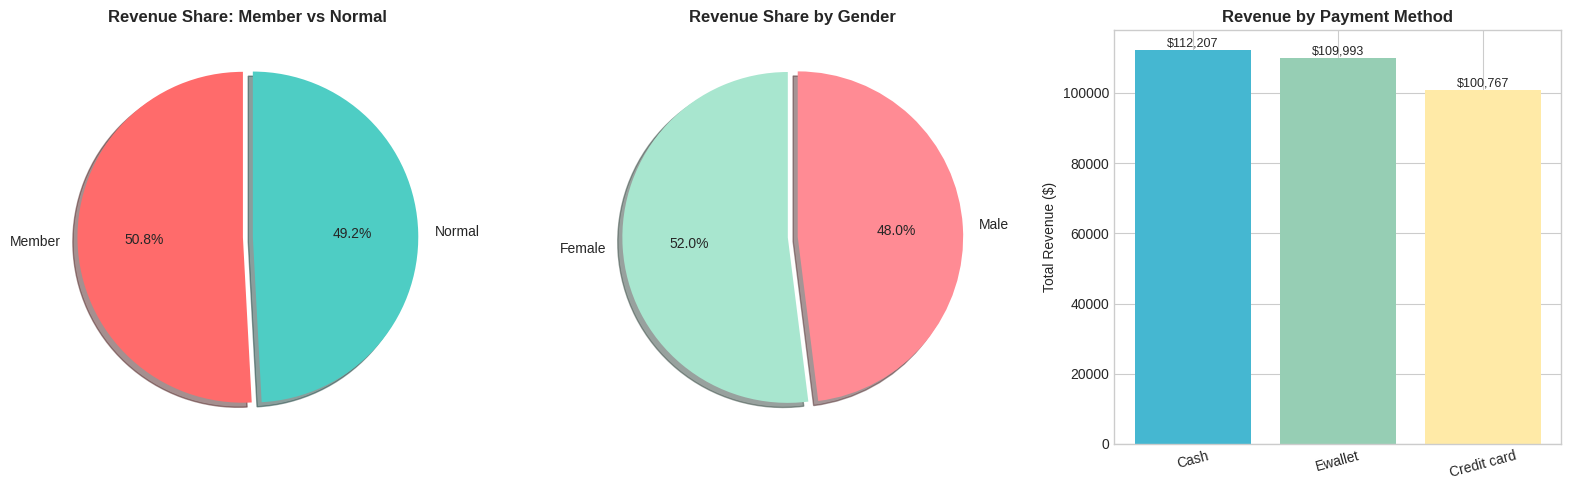

In [26]:
# ======================
# 10. Customer Type + Gender + Payment Analysis
# ======================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Member vs Normal (Revenue Share)
cust_rev = df.groupby("customer_type")["total"].sum()
axes[0].pie(cust_rev, labels=cust_rev.index, autopct="%1.1f%%", startangle=90,
            colors=["#FF6B6B", "#4ECDC4"], explode=[0.03, 0.03], shadow=True)
axes[0].set_title("Revenue Share: Member vs Normal", fontweight="bold")

# 2. Gender Revenue Share
gender_rev = df.groupby("gender")["total"].sum()
axes[1].pie(gender_rev, labels=gender_rev.index, autopct="%1.1f%%", startangle=90,
            colors=["#A8E6CF", "#FF8B94"], explode=[0.03, 0.03], shadow=True)
axes[1].set_title("Revenue Share by Gender", fontweight="bold")

# 3. Payment Method
pay_rev = df.groupby("payment")["total"].sum().sort_values(ascending=False)
axes[2].bar(pay_rev.index, pay_rev.values, color=["#45B7D1", "#96CEB4", "#FFEAA7"])
axes[2].set_title("Revenue by Payment Method", fontweight="bold")
axes[2].set_ylabel("Total Revenue ($)")
axes[2].tick_params(axis='x', rotation=15)

for i, v in enumerate(pay_rev.values):
    axes[2].text(i, v + 1000, f"${v:,.0f}", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

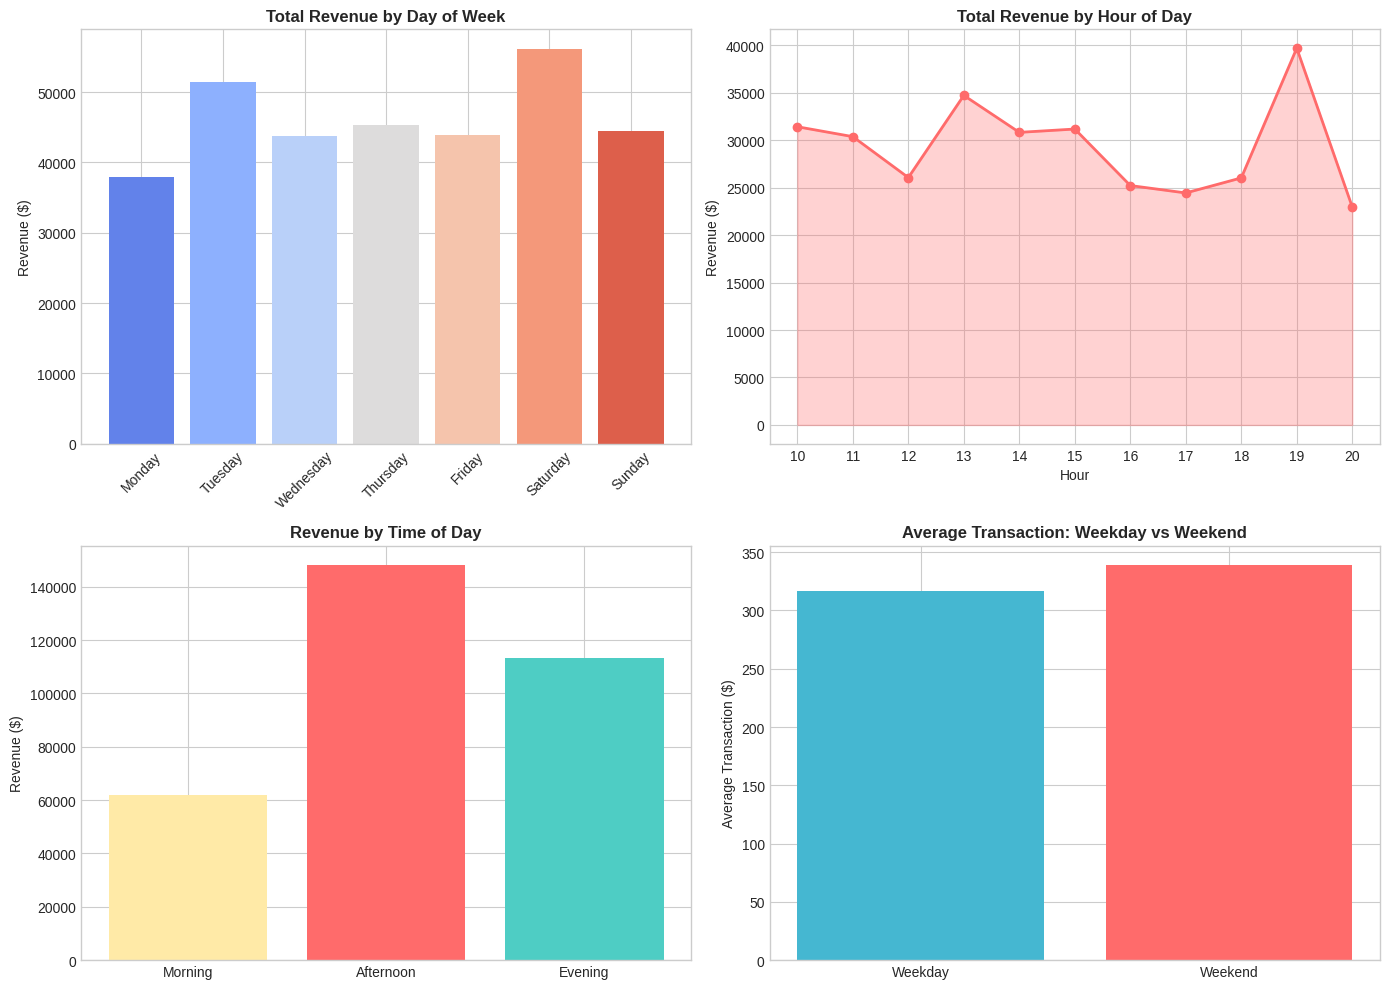

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Revenue by Day of Week
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_rev = df.groupby("day_of_week")["total"].sum().reindex(day_order)
axes[0, 0].bar(day_rev.index, day_rev.values, color=sns.color_palette("coolwarm", 7))
axes[0, 0].set_title("Total Revenue by Day of Week", fontweight="bold")
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].set_ylabel("Revenue ($)")

# 2. Revenue by Hour
hour_rev = df.groupby("hour")["total"].sum()
axes[0, 1].plot(hour_rev.index, hour_rev.values, marker="o", linewidth=2, color="#FF6B6B")
axes[0, 1].fill_between(hour_rev.index, hour_rev.values, alpha=0.3, color="#FF6B6B")
axes[0, 1].set_title("Total Revenue by Hour of Day", fontweight="bold")
axes[0, 1].set_xlabel("Hour")
axes[0, 1].set_ylabel("Revenue ($)")
axes[0, 1].set_xticks(range(10, 21))

# 3. Revenue by Time of Day
tod_order = ["Morning", "Afternoon", "Evening", "Night"]
tod_rev = df.groupby("time_of_day")["total"].sum().reindex(tod_order)
axes[1, 0].bar(tod_rev.index, tod_rev.values, color=["#FFEAA7", "#FF6B6B", "#4ECDC4", "#45B7D1"])
axes[1, 0].set_title("Revenue by Time of Day", fontweight="bold")
axes[1, 0].set_ylabel("Revenue ($)")

# 4. Weekday vs Weekend (Average Transaction)
weekend_avg = df.groupby("is_weekend")["total"].mean()
axes[1, 1].bar(["Weekday", "Weekend"], weekend_avg.values, color=["#45B7D1", "#FF6B6B"])
axes[1, 1].set_title("Average Transaction: Weekday vs Weekend", fontweight="bold")
axes[1, 1].set_ylabel("Average Transaction ($)")

plt.tight_layout()
plt.show()

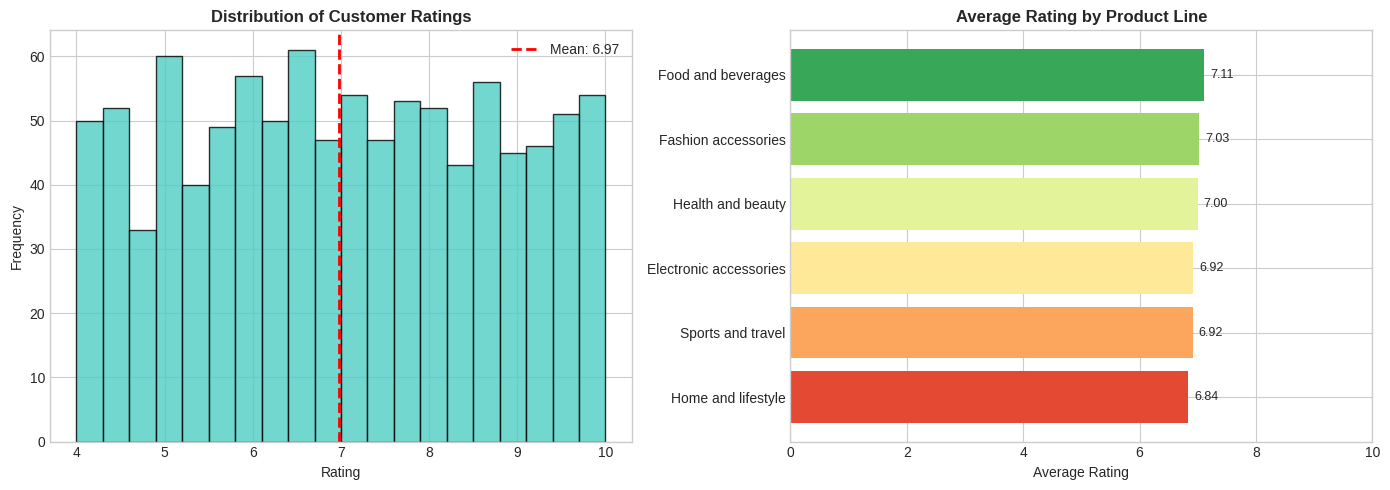

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribution of Ratings
axes[0].hist(df["rating"], bins=20, color="#4ECDC4", edgecolor="black", alpha=0.8)
axes[0].axvline(df["rating"].mean(), color="red", linestyle="--", linewidth=2,
                label=f"Mean: {df['rating'].mean():.2f}")
axes[0].set_title("Distribution of Customer Ratings", fontweight="bold")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# 2. Average Rating by Product Line
rating_prod = df.groupby("product_line")["rating"].mean().sort_values(ascending=True)
axes[1].barh(rating_prod.index, rating_prod.values, color=sns.color_palette("RdYlGn", len(rating_prod)))
axes[1].set_title("Average Rating by Product Line", fontweight="bold")
axes[1].set_xlabel("Average Rating")
axes[1].set_xlim(0, 10)

for i, v in enumerate(rating_prod.values):
    axes[1].text(v + 0.1, i, f"{v:.2f}", va="center", fontsize=9)

plt.tight_layout()
plt.show()

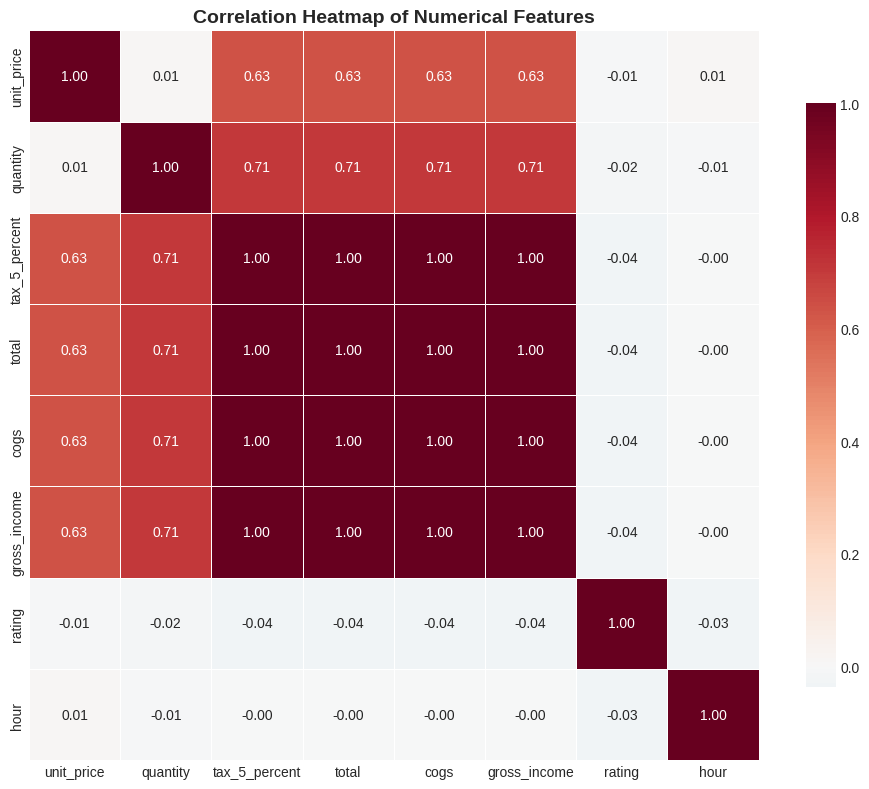

In [30]:


numeric_cols = ["unit_price", "quantity", "tax_5_percent", "total",
                "cogs", "gross_income", "rating", "hour"]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [41]:

# حساب أهم المؤشرات
top_city = df.groupby("city")["total"].sum().idxmax()
top_city_rev = df.groupby("city")["total"].sum().max()

top_product = df.groupby("product_line")["total"].sum().idxmax()
top_product_rev = df.groupby("product_line")["total"].sum().max()

best_day = df.groupby("day_of_week")["total"].sum().idxmax()
best_hour = df.groupby("hour")["total"].sum().idxmax()

member_avg = df[df["customer_type"] == "Member"]["total"].mean()
normal_avg = df[df["customer_type"] == "Normal"]["total"].mean()




In [40]:
print(f"""
1.  Highest Revenue City       : {top_city} (${top_city_rev:,.2f})
2.  Best Selling Product Line  : {top_product} (${top_product_rev:,.2f})
3.  Best Day for Sales         : {best_day}
4.  Peak Hour                  : {best_hour}:00
5.  Member Avg Transaction     : ${member_avg:.2f}
   Normal Avg Transaction        : ${normal_avg:.2f}
6.  Overall Average Rating     : {df['rating'].mean():.2f} / 10
7.  Most Used Payment Method   : {df['payment'].mode()[0]}
8.  Average Items per Invoice  : {df['quantity'].mean():.1f}
9.  Total Revenue              : ${df['total'].sum():,.2f}
10.  Total Gross Income         : ${df['gross_income'].sum():,.2f}
""")



1.  Highest Revenue City       : Naypyitaw ($110,568.71)
2.  Best Selling Product Line  : Food and beverages ($56,144.84)
3.  Best Day for Sales         : Saturday
4.  Peak Hour                  : 19:00
5.  Member Avg Transaction     : $327.79
   Normal Avg Transaction        : $318.12
6.  Overall Average Rating     : 6.97 / 10
7.  Most Used Payment Method   : Ewallet
8.  Average Items per Invoice  : 5.5
9.  Total Revenue              : $322,966.75
10.  Total Gross Income         : $15,379.37



In [33]:
# ======================
# 15. Save All Figures as PNG
# ======================

import os

# إنشاء مجلد لحفظ الرسومات لو مش موجود
os.makedirs("outputs/figures", exist_ok=True)

# ------------------- 1. Revenue by City -------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

city_rev = df.groupby("city")["total"].sum().sort_values(ascending=True)
axes[0].barh(city_rev.index, city_rev.values, color=["#FF6B6B", "#4ECDC4", "#45B7D1"])
axes[0].set_title("Total Revenue by City", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Total Revenue ($)")
for i, v in enumerate(city_rev.values):
    axes[0].text(v + 500, i, f"${v:,.0f}", va="center", fontsize=10)

city_avg = df.groupby("city")["total"].mean().sort_values(ascending=True)
axes[1].barh(city_avg.index, city_avg.values, color=["#FF6B6B", "#4ECDC4", "#45B7D1"])
axes[1].set_title("Average Transaction Value by City", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Average Transaction ($)")
for i, v in enumerate(city_avg.values):
    axes[1].text(v + 2, i, f"${v:.1f}", va="center", fontsize=10)

plt.tight_layout()
plt.savefig("outputs/figures/01_revenue_by_city.png", dpi=150, bbox_inches="tight")
plt.close()
print("✅ Saved: 01_revenue_by_city.png")

# ------------------- 2. Product Line -------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

prod_rev = df.groupby("product_line")["total"].sum().sort_values(ascending=True)
axes[0].barh(prod_rev.index, prod_rev.values, color=sns.color_palette("viridis", len(prod_rev)))
axes[0].set_title("Total Revenue by Product Line", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Total Revenue ($)")

prod_qty = df.groupby("product_line")["quantity"].sum().sort_values(ascending=True)
axes[1].barh(prod_qty.index, prod_qty.values, color=sns.color_palette("magma", len(prod_qty)))
axes[1].set_title("Total Quantity Sold by Product Line", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Quantity Sold")

plt.tight_layout()
plt.savefig("outputs/figures/02_product_line_analysis.png", dpi=150, bbox_inches="tight")
plt.close()
print("✅ Saved: 02_product_line_analysis.png")

# ------------------- 3. Customer & Payment -------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cust_rev = df.groupby("customer_type")["total"].sum()
axes[0].pie(cust_rev, labels=cust_rev.index, autopct="%1.1f%%", startangle=90,
            colors=["#FF6B6B", "#4ECDC4"], explode=[0.03, 0.03], shadow=True)
axes[0].set_title("Revenue Share: Member vs Normal", fontweight="bold")

gender_rev = df.groupby("gender")["total"].sum()
axes[1].pie(gender_rev, labels=gender_rev.index, autopct="%1.1f%%", startangle=90,
            colors=["#A8E6CF", "#FF8B94"], explode=[0.03, 0.03], shadow=True)
axes[1].set_title("Revenue Share by Gender", fontweight="bold")

pay_rev = df.groupby("payment")["total"].sum().sort_values(ascending=False)
axes[2].bar(pay_rev.index, pay_rev.values, color=["#45B7D1", "#96CEB4", "#FFEAA7"])
axes[2].set_title("Revenue by Payment Method", fontweight="bold")
axes[2].set_ylabel("Total Revenue ($)")
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig("outputs/figures/03_customer_payment_analysis.png", dpi=150, bbox_inches="tight")
plt.close()
print("✅ Saved: 03_customer_payment_analysis.png")

# ------------------- 4. Time Analysis -------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_rev = df.groupby("day_of_week")["total"].sum().reindex(day_order)
axes[0, 0].bar(day_rev.index, day_rev.values, color=sns.color_palette("coolwarm", 7))
axes[0, 0].set_title("Total Revenue by Day of Week", fontweight="bold")
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].set_ylabel("Revenue ($)")

hour_rev = df.groupby("hour")["total"].sum()
axes[0, 1].plot(hour_rev.index, hour_rev.values, marker="o", linewidth=2, color="#FF6B6B")
axes[0, 1].fill_between(hour_rev.index, hour_rev.values, alpha=0.3, color="#FF6B6B")
axes[0, 1].set_title("Total Revenue by Hour of Day", fontweight="bold")
axes[0, 1].set_xlabel("Hour")
axes[0, 1].set_ylabel("Revenue ($)")
axes[0, 1].set_xticks(range(10, 21))

tod_order = ["Morning", "Afternoon", "Evening", "Night"]
tod_rev = df.groupby("time_of_day")["total"].sum().reindex(tod_order)
axes[1, 0].bar(tod_rev.index, tod_rev.values, color=["#FFEAA7", "#FF6B6B", "#4ECDC4", "#45B7D1"])
axes[1, 0].set_title("Revenue by Time of Day", fontweight="bold")
axes[1, 0].set_ylabel("Revenue ($)")

weekend_avg = df.groupby("is_weekend")["total"].mean()
axes[1, 1].bar(["Weekday", "Weekend"], weekend_avg.values, color=["#45B7D1", "#FF6B6B"])
axes[1, 1].set_title("Average Transaction: Weekday vs Weekend", fontweight="bold")
axes[1, 1].set_ylabel("Average Transaction ($)")

plt.tight_layout()
plt.savefig("outputs/figures/04_time_analysis.png", dpi=150, bbox_inches="tight")
plt.close()
print("✅ Saved: 04_time_analysis.png")

# ------------------- 5. Rating Analysis -------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["rating"], bins=20, color="#4ECDC4", edgecolor="black", alpha=0.8)
axes[0].axvline(df["rating"].mean(), color="red", linestyle="--", linewidth=2,
                label=f"Mean: {df['rating'].mean():.2f}")
axes[0].set_title("Distribution of Customer Ratings", fontweight="bold")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Frequency")
axes[0].legend()

rating_prod = df.groupby("product_line")["rating"].mean().sort_values(ascending=True)
axes[1].barh(rating_prod.index, rating_prod.values, color=sns.color_palette("RdYlGn", len(rating_prod)))
axes[1].set_title("Average Rating by Product Line", fontweight="bold")
axes[1].set_xlabel("Average Rating")
axes[1].set_xlim(0, 10)

plt.tight_layout()
plt.savefig("outputs/figures/05_rating_analysis.png", dpi=150, bbox_inches="tight")
plt.close()
print("✅ Saved: 05_rating_analysis.png")

# ------------------- 6. Correlation Heatmap -------------------
numeric_cols = ["unit_price", "quantity", "tax_5_percent", "total",
                "cogs", "gross_income", "rating", "hour"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, fmt=".2f",
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/figures/06_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.close()
print("✅ Saved: 06_correlation_heatmap.png")

# ------------------- 7. Sales Trend Line Chart -------------------
daily_sales = df.groupby(df["datetime"].dt.date)["total"].sum().reset_index()
daily_sales.columns = ["date", "total_sales"]
daily_sales["date"] = pd.to_datetime(daily_sales["date"])
daily_sales["moving_avg"] = daily_sales["total_sales"].rolling(window=7).mean()

plt.figure(figsize=(14, 6))
plt.plot(daily_sales["date"], daily_sales["total_sales"],
         color="#FF6B6B", linewidth=2, marker="o", markersize=4, label="Daily Sales")
plt.plot(daily_sales["date"], daily_sales["moving_avg"],
         color="#45B7D1", linewidth=2.5, linestyle="--", label="7-Day Moving Average")
plt.title("Sales Trend Over Time (Jan - Mar 2019)", fontsize=16, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Total Sales ($)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outputs/figures/07_sales_trend_line.png", dpi=150, bbox_inches="tight")
plt.close()
print("✅ Saved: 07_sales_trend_line.png")

print("\n" + "="*50)
print("🎉 All figures saved successfully in: outputs/figures/")
print("="*50)

✅ Saved: 01_revenue_by_city.png
✅ Saved: 02_product_line_analysis.png
✅ Saved: 03_customer_payment_analysis.png
✅ Saved: 04_time_analysis.png
✅ Saved: 05_rating_analysis.png
✅ Saved: 06_correlation_heatmap.png
✅ Saved: 07_sales_trend_line.png

🎉 All figures saved successfully in: outputs/figures/


In [49]:
!git config --global user.email "your-email@example.com"
!git config --global user.name "Your Name"

!git init
!git add .
!git commit -m "Initial commit - Supermarket Sales Analysis"
!git branch -M main
!git remote add origin https://github.com/2y9838c/supermarket-analysis.git
!git push -u origin main

Reinitialized existing Git repository in /content/.git/
[main (root-commit) e2f18c5] Initial commit - Supermarket Sales Analysis
 29 files changed, 52091 insertions(+)
 create mode 100644 .config/.last_opt_in_prompt.yaml
 create mode 100644 .config/.last_survey_prompt.yaml
 create mode 100644 .config/.last_update_check.json
 create mode 100644 .config/active_config
 create mode 100644 .config/config_sentinel
 create mode 100644 .config/configurations/config_default
 create mode 100644 .config/default_configs.db
 create mode 100644 .config/gce
 create mode 100644 .config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
 create mode 100644 .config/logs/2026.10.02/13.49.46.128557.log
 create mode 100644 .config/logs/2026.10.02/13.50.08.874802.log
 create mode 100644 .config/logs/2026.10.02/13.50.14.261149.log
 create mode 100644 .config/logs/2026.10.02/13.50.15.366402.log
 create mode 100644 .config/logs/2026.10.02/13.50.21.004336.log
 create mode 100644 .config/logs/2026.10

In [50]:
!git remote set-url origin https://github.com/2y9838c/supermarket-analysis.git
!git push -u origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [48]:
git init
git add README.md
git commit -m "first commit"
git branch -M main
git remote add origin https://github.com/2y9838c/supermarket-analysis.git
git push -u origin main

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/.git/
fatal: pathspec 'README.md' did not match any files
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@4b41010f0e43.(none)')
error: src refspec main does not match any
error: failed to push some refs to